# Lesson 16 — Regression on Real Data: Preprocessing, Regularisation and Error Analysis

**Objective:** Predict a continuous outcome from messy, mixed-type data, using leakage-safe preprocessing with `ColumnTransformer`, regularised linear models and gradient boosting, evaluated with MAE, RMSE and R².

**Data:** Ames Housing dataset (OpenML ID 42165) — 1,460 residential property sales in Ames, Iowa (2006–2010), with 79 explanatory variables. Compiled by Dean De Cock for teaching regression. Used here for education only.

In [1]:
# Lesson 16 — Step 1: Load and inspect the data
import numpy as np
import pandas as pd
from sklearn.datasets import fetch_openml

housing = fetch_openml(data_id=42165, as_frame=True)
print("DATASET:", housing.details["name"], "| OpenML ID:", housing.details["id"])

df = housing.frame.copy()
if "Id" in df.columns:
    df = df.drop(columns="Id")  # row identifier, not a predictor

target = "SalePrice"
numeric_cols = df.drop(columns=target).select_dtypes(include="number").columns
categorical_cols = df.drop(columns=target).select_dtypes(exclude="number").columns

print("\nDATASET SHAPE:", df.shape)
print("Numeric predictors:    ", len(numeric_cols))
print("Categorical predictors:", len(categorical_cols))

print("\nTARGET — SALE PRICE (USD):")
print(df[target].describe().round(0))
print(f"Skewness: {df[target].skew():.2f}")

missing = df.isna().mean().mul(100).round(1)
missing = missing[missing > 0].sort_values(ascending=False)
print(f"\nCOLUMNS WITH MISSING VALUES: {len(missing)} of {df.shape[1]}")
display(missing.head(15).to_frame("Missing (%)"))

DATASET: house_prices | OpenML ID: 42165

DATASET SHAPE: (1460, 80)
Numeric predictors:     36
Categorical predictors: 43

TARGET — SALE PRICE (USD):
count      1460.0
mean     180921.0
std       79443.0
min       34900.0
25%      129975.0
50%      163000.0
75%      214000.0
max      755000.0
Name: SalePrice, dtype: float64
Skewness: 1.88

COLUMNS WITH MISSING VALUES: 19 of 80


,Missing (%)
PoolQC,99.5
MiscFeature,96.3
Alley,93.8
Fence,80.8
FireplaceQu,47.3
LotFrontage,17.7
GarageCond,5.5
GarageType,5.5
GarageYrBlt,5.5
GarageFinish,5.5


## Step 2 — Target Distribution and the Meaning of Missing Values

Sale price is right-skewed, so models will be trained on log(price) and predictions converted back to dollars for evaluation.

For many categorical columns, a missing value means the feature does not exist (for example, no pool or no garage), as stated in the dataset documentation. This is verified against the related numeric columns and recoded as an explicit "None" category. Values that are genuinely unknown, such as lot frontage, are left missing for imputation inside the model pipeline.

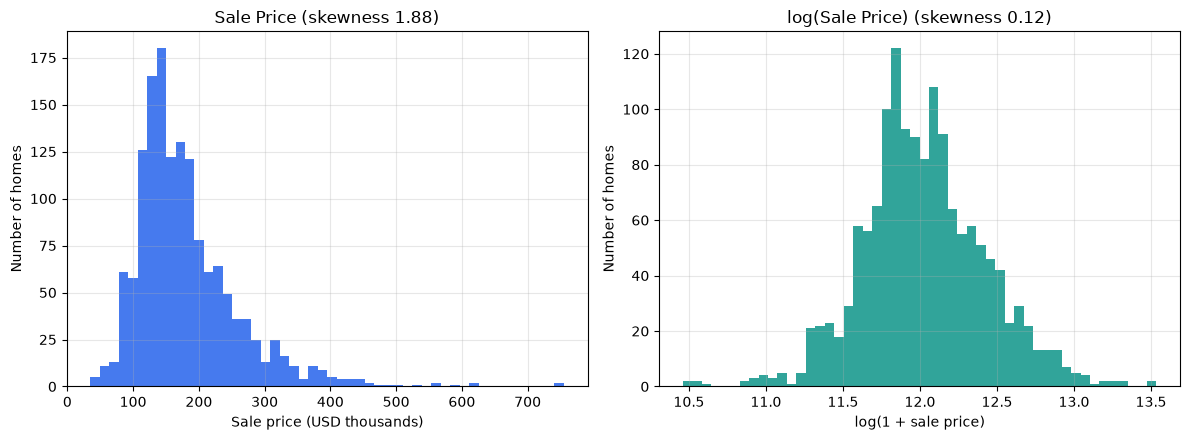

CONSISTENCY CHECKS — missing category vs related measurement:
  No pool (PoolQC missing, PoolArea = 0): 1453 of 1453 missing rows agree
  No fireplace (FireplaceQu missing, Fireplaces = 0): 690 of 690 missing rows agree
  No garage (GarageType missing, GarageArea = 0): 81 of 81 missing rows agree
  No basement (BsmtQual missing, TotalBsmtSF = 0): 37 of 37 missing rows agree

MISSING VALUES REMAINING (genuinely unknown — imputed in the pipeline):


,Missing count
LotFrontage,259
GarageYrBlt,81
MasVnrArea,8
Electrical,1


In [2]:
# Lesson 16 — Step 2: Target distribution and the meaning of missing values
import matplotlib.pyplot as plt

# --- 2a. Raw vs log-transformed sale price ---
log_price = np.log1p(df[target])
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
ax1.hist(df[target] / 1000, bins=50, color="#2563EB", alpha=0.85)
ax1.set(title=f"Sale Price (skewness {df[target].skew():.2f})",
        xlabel="Sale price (USD thousands)", ylabel="Number of homes")
ax2.hist(log_price, bins=50, color="#0D9488", alpha=0.85)
ax2.set(title=f"log(Sale Price) (skewness {log_price.skew():.2f})",
        xlabel="log(1 + sale price)", ylabel="Number of homes")
for ax in (ax1, ax2):
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# --- 2b. Check that "missing" means "feature does not exist" ---
checks = {
    "No pool (PoolQC missing, PoolArea = 0)":
        (df["PoolQC"].isna(), df["PoolArea"] == 0),
    "No fireplace (FireplaceQu missing, Fireplaces = 0)":
        (df["FireplaceQu"].isna(), df["Fireplaces"] == 0),
    "No garage (GarageType missing, GarageArea = 0)":
        (df["GarageType"].isna(), df["GarageArea"] == 0),
    "No basement (BsmtQual missing, TotalBsmtSF = 0)":
        (df["BsmtQual"].isna(), df["TotalBsmtSF"] == 0),
}
print("CONSISTENCY CHECKS — missing category vs related measurement:")
for label, (is_missing, is_zero) in checks.items():
    print(f"  {label}: {(is_missing & is_zero).sum()} of {is_missing.sum()} missing rows agree")

# --- 2c. Recode structural missing values as an explicit "None" category ---
none_cols = ["PoolQC", "MiscFeature", "Alley", "Fence", "FireplaceQu",
             "GarageType", "GarageFinish", "GarageQual", "GarageCond",
             "BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1", "BsmtFinType2",
             "MasVnrType"]
none_cols = [c for c in none_cols if c in df.columns]

df[categorical_cols] = df[categorical_cols].astype("object")  # plain text, so "None" can be added
df[none_cols] = df[none_cols].fillna("None")

remaining = df.isna().sum()
remaining = remaining[remaining > 0].sort_values(ascending=False)
print("\nMISSING VALUES REMAINING (genuinely unknown — imputed in the pipeline):")
display(remaining.to_frame("Missing count"))

## Step 3 — Train/Test Split, Preprocessing Pipeline and Baseline

The data is split 80/20 into training and test sets; the test set is held back until the final evaluation. A `ColumnTransformer` applies median imputation (with missing-value indicators) and scaling to numeric columns, and most-frequent imputation with one-hot encoding to categorical columns. Categories seen fewer than 10 times are grouped as "infrequent" to avoid sparse, noisy columns. Models predict log(price), and predictions are converted back to dollars before scoring.

A baseline that predicts the median training price for every home sets the minimum any model must beat.

In [3]:
# Lesson 16 — Step 3: Split, preprocessing pipeline and baseline
from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyRegressor

X = df.drop(columns=target)
y = df[target]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)
print("Training set:", X_train.shape, f"| median price ${y_train.median():,.0f}")
print("Test set:    ", X_test.shape, f"| median price ${y_test.median():,.0f}")

def make_preprocessor(scale=True):
    """Separate preparation for numeric and categorical columns."""
    numeric_steps = [("imputer", SimpleImputer(strategy="median", add_indicator=True))]
    if scale:
        numeric_steps.append(("scaler", StandardScaler()))
    categorical_steps = [
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist",
                                 min_frequency=10, sparse_output=False)),
    ]
    return ColumnTransformer([
        ("num", Pipeline(numeric_steps), list(numeric_cols)),
        ("cat", Pipeline(categorical_steps), list(categorical_cols)),
    ])

def log_target(regressor):
    """Train on log(price); return predictions in dollars."""
    return TransformedTargetRegressor(regressor=regressor,
                                      func=np.log1p, inverse_func=np.expm1)

# How many model inputs does preprocessing create?
n_features = make_preprocessor().fit(X_train).transform(X_train).shape[1]
print(f"\nColumns after preprocessing: {n_features} (from {X.shape[1]} original)")

# Shared cross-validation setup for every model in this lesson
cv = KFold(n_splits=5, shuffle=True, random_state=42)
scoring = {
    "MAE": "neg_mean_absolute_error",
    "RMSE": "neg_root_mean_squared_error",
    "MAPE": "neg_mean_absolute_percentage_error",
    "R2": "r2",
}
cv_results = []

def evaluate_cv(name, model):
    """Cross-validate on training data; errors reported in dollars, MAPE in %."""
    s = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    row = {
        "Model": name,
        "MAE ($)": -s["test_MAE"].mean(),
        "RMSE ($)": -s["test_RMSE"].mean(),
        "MAPE (%)": -s["test_MAPE"].mean() * 100,
        "R2": s["test_R2"].mean(),
        "R2 SD": s["test_R2"].std(),
    }
    cv_results.append(row)
    return row

evaluate_cv("Baseline (median price)", DummyRegressor(strategy="median"))

print("\nCROSS-VALIDATION RESULTS (training data, 5 folds):")
display(pd.DataFrame(cv_results).round(3))

Training set: (1168, 79) | median price $165,000
Test set:     (292, 79) | median price $154,150

Columns after preprocessing: 256 (from 79 original)



CROSS-VALIDATION RESULTS (training data, 5 folds):


,Model,MAE ($),RMSE ($),MAPE (%),R2,R2 SD
0,Baseline (median price),54586.139,78860.09,31.181,-0.046,0.014


## Step 4 — Linear Regression, Ridge and Lasso

With 256 input columns and 1,168 training homes, an unregularised linear model risks overfitting. Ridge (L2) shrinks all coefficients; Lasso (L1) can set coefficients exactly to zero, performing embedded feature selection. The penalty strength (alpha) is selected by internal cross-validation within each training fold, so the outer cross-validation estimate remains unbiased.

In [4]:
# Lesson 16 — Step 4: Linear Regression, Ridge and Lasso
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV

def linear_pipeline(model):
    return log_target(Pipeline([("prep", make_preprocessor()), ("model", model)]))

linear_models = {
    "Linear Regression": linear_pipeline(LinearRegression()),
    "Ridge (alpha tuned)": linear_pipeline(RidgeCV(alphas=np.logspace(-2, 3, 30))),
    "Lasso (alpha tuned)": linear_pipeline(LassoCV(alphas=np.logspace(-4, -1, 30),
                                                   cv=5, max_iter=20000)),
}
for name, model in linear_models.items():
    evaluate_cv(name, model)

print("CROSS-VALIDATION RESULTS SO FAR:")
display(pd.DataFrame(cv_results).round(3))

# --- Inspect the Lasso fitted on the full training set ---
lasso = linear_models["Lasso (alpha tuned)"].fit(X_train, y_train)
lasso_inner = lasso.regressor_
lasso_model = lasso_inner.named_steps["model"]
feature_names = (lasso_inner.named_steps["prep"].get_feature_names_out()
                 .astype(str))
feature_names = np.char.replace(np.char.replace(feature_names, "num__", ""), "cat__", "")

coefs = pd.Series(lasso_model.coef_, index=feature_names)
kept = coefs[coefs != 0]
print(f"\nLasso alpha chosen: {lasso_model.alpha_:.5f}")
print(f"Columns kept by Lasso: {len(kept)} of {len(coefs)} "
      f"({len(coefs) - len(kept)} set exactly to zero)")

top = kept.reindex(kept.abs().sort_values(ascending=False).index).head(12)
print("\nLARGEST LASSO EFFECTS (log-price model):")
display(pd.DataFrame({
    "Coefficient": top.round(4),
    "Approx. effect on price (%)": ((np.exp(top) - 1) * 100).round(1),
}))

CROSS-VALIDATION RESULTS SO FAR:


,Model,MAE ($),RMSE ($),MAPE (%),R2,R2 SD
0,Baseline (median price),54586.139,78860.090,31.181,-0.046,0.014
1,Linear Regression,18346.506,41804.932,10.573,0.642,0.371
2,Ridge (alpha tuned),17544.509,42252.204,9.971,0.601,0.503
3,Lasso (alpha tuned),17261.003,40681.955,9.894,0.636,0.443



Lasso alpha chosen: 0.00085
Columns kept by Lasso: 102 of 256 (154 set exactly to zero)

LARGEST LASSO EFFECTS (log-price model):


,Coefficient,Approx. effect on price (%)
Neighborhood_StoneBr,0.1034,10.9
GrLivArea,0.1031,10.9
Neighborhood_Crawfor,0.0947,9.9
Exterior1st_BrkFace,0.0889,9.3
OverallQual,0.0840,8.8
Neighborhood_NridgHt,0.0765,8.0
MSZoning_RM,-0.0595,-5.8
LandContour_Bnk,-0.0542,-5.3
BsmtExposure_Gd,0.0520,5.3
Functional_Typ,0.0519,5.3


## Step 5 — Diagnosing Unstable Cross-Validation Results

The linear models show a large spread in R² across folds (SD 0.37–0.50) and RMSE far above MAE, which suggests a small number of very large errors. Out-of-fold predictions are examined to identify which homes cause them.

LASSO R² BY FOLD: [ 0.903  0.714 -0.237  0.901  0.9  ]



LARGEST OUT-OF-FOLD ERRORS:


,Actual ($),Predicted ($),Error ($),GrLivArea (sq ft),OverallQual,SaleCondition,Abs error ($)
1298,160000,1516972.0,1356972.0,5642,10,Partial,1356972.0
523,184750,686908.0,502158.0,4676,10,Partial,502158.0
1182,745000,571673.0,-173327.0,4476,10,Abnorml,173327.0
803,582933,442298.0,-140635.0,2822,9,Partial,140635.0
688,392000,253346.0,-138654.0,1419,8,Partial,138654.0
1324,147000,277991.0,130991.0,1795,8,Partial,130991.0
440,555000,424061.0,-130939.0,2402,10,Normal,130939.0
1181,392500,262609.0,-129891.0,1652,8,Partial,129891.0


Share of total squared error from the 3 worst homes: 77.6%


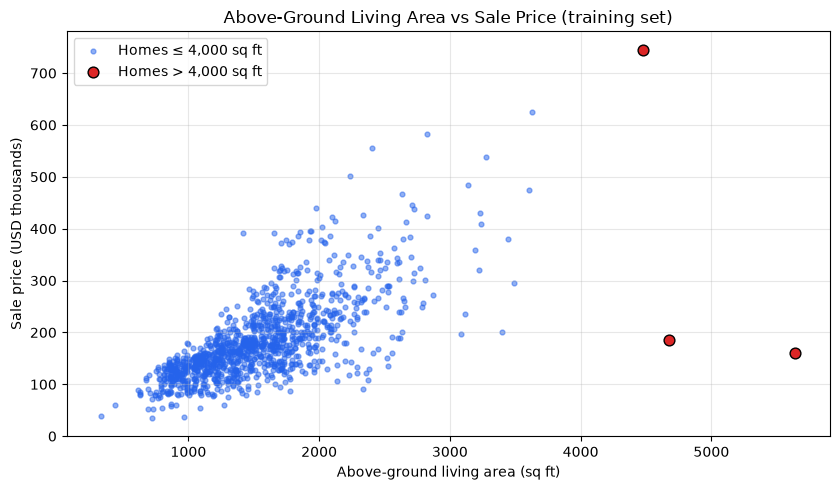


HOMES OVER 4,000 SQ FT:
  Training set: 3 | Test set: 1


In [5]:
# Lesson 16 — Step 5: Diagnose unstable folds
from sklearn.model_selection import cross_val_predict

lasso_pipe = linear_models["Lasso (alpha tuned)"]

# R² in each fold
fold_r2 = cross_validate(lasso_pipe, X_train, y_train, cv=cv, scoring="r2")["test_score"]
print("LASSO R² BY FOLD:", np.round(fold_r2, 3))

# Out-of-fold predictions: each home predicted by a model that never saw it
oof_pred = cross_val_predict(lasso_pipe, X_train, y_train, cv=cv)
errors = pd.DataFrame({
    "Actual ($)": y_train,
    "Predicted ($)": oof_pred.round(0),
    "Error ($)": (oof_pred - y_train).round(0),
    "GrLivArea (sq ft)": X_train["GrLivArea"],
    "OverallQual": X_train["OverallQual"],
    "SaleCondition": X_train["SaleCondition"],
})
errors["Abs error ($)"] = errors["Error ($)"].abs()
worst = errors.sort_values("Abs error ($)", ascending=False).head(8)
print("\nLARGEST OUT-OF-FOLD ERRORS:")
display(worst)

share = worst["Abs error ($)"].head(3).pow(2).sum() / errors["Abs error ($)"].pow(2).sum()
print(f"Share of total squared error from the 3 worst homes: {share:.1%}")

# Living area vs price, highlighting very large homes
large = X_train["GrLivArea"] > 4000
fig, ax = plt.subplots(figsize=(8.5, 5))
ax.scatter(X_train.loc[~large, "GrLivArea"], y_train[~large] / 1000,
           s=12, alpha=0.5, color="#2563EB", label="Homes ≤ 4,000 sq ft")
ax.scatter(X_train.loc[large, "GrLivArea"], y_train[large] / 1000,
           s=60, color="#DC2626", edgecolor="black", label="Homes > 4,000 sq ft")
ax.set(title="Above-Ground Living Area vs Sale Price (training set)",
       xlabel="Above-ground living area (sq ft)", ylabel="Sale price (USD thousands)")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

print("\nHOMES OVER 4,000 SQ FT:")
print("  Training set:", int(large.sum()), "| Test set:", int((X_test["GrLivArea"] > 4000).sum()))

### Step 5b — Scope Restriction: Homes up to 4,000 sq ft

The diagnosis showed that two very large homes (4,676 and 5,642 sq ft), both partial sales at ordinary prices, caused one cross-validation fold to collapse (R² = −0.24), and that the three largest homes accounted for 77.6% of total squared error. Following the dataset author's recommendation, homes with more than 4,000 sq ft of above-ground living area are removed from both training and test sets. The model's stated scope is therefore homes up to 4,000 sq ft.

In [6]:
# Lesson 16 — Step 5b: Apply the scope rule (≤ 4,000 sq ft) and re-evaluate
in_scope_train = X_train["GrLivArea"] <= 4000
in_scope_test = X_test["GrLivArea"] <= 4000
print(f"Removed from training: {(~in_scope_train).sum()} | from test: {(~in_scope_test).sum()}")

X_train, y_train = X_train[in_scope_train], y_train[in_scope_train]
X_test, y_test = X_test[in_scope_test], y_test[in_scope_test]
print("Training set:", X_train.shape, "| Test set:", X_test.shape)

# Re-run the baseline and linear models on the in-scope data
cv_results = []
evaluate_cv("Baseline (median price)", DummyRegressor(strategy="median"))
for name, model in linear_models.items():
    evaluate_cv(name, model)

print("\nCROSS-VALIDATION RESULTS (homes ≤ 4,000 sq ft):")
display(pd.DataFrame(cv_results).round(3))

fold_r2 = cross_validate(lasso_pipe, X_train, y_train, cv=cv, scoring="r2")["test_score"]
print("LASSO R² BY FOLD:", np.round(fold_r2, 3))

Removed from training: 3 | from test: 1
Training set: (1165, 79) | Test set: (291, 79)



CROSS-VALIDATION RESULTS (homes ≤ 4,000 sq ft):


,Model,MAE ($),RMSE ($),MAPE (%),R2,R2 SD
0,Baseline (median price),54301.583,77019.854,31.277,-0.047,0.020
1,Linear Regression,14573.354,21475.578,8.625,0.918,0.009
2,Ridge (alpha tuned),13735.313,20099.912,8.133,0.929,0.004
3,Lasso (alpha tuned),13458.872,19818.013,8.010,0.931,0.005


LASSO R² BY FOLD: [0.924 0.939 0.932 0.932 0.926]


## Step 6 — The Boosting Family: AdaBoost, Gradient Boosting, HistGradientBoosting, XGBoost and LightGBM

AdaBoost reweights the observations that previous trees predicted poorly. Gradient boosting instead fits each new tree to the remaining errors of the ensemble; HistGradientBoosting, XGBoost and LightGBM are optimised implementations of this idea. All models use the same tree-friendly preprocessing (no scaling; categories encoded as integers), comparable settings (learning rate 0.05, shallow trees, row subsampling where available) and the same cross-validation folds.

In [7]:
# Lesson 16 — Step 6: The boosting family compared
import time
from sklearn.preprocessing import OrdinalEncoder
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (AdaBoostRegressor, GradientBoostingRegressor,
                              HistGradientBoostingRegressor)

def tree_preprocessor():
    """Trees need no scaling or one-hot encoding: categories become integer codes."""
    return ColumnTransformer([
        ("num", SimpleImputer(strategy="median", add_indicator=True), list(numeric_cols)),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("ordinal", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)),
        ]), list(categorical_cols)),
    ])

def tree_pipeline(model):
    return log_target(Pipeline([("prep", tree_preprocessor()), ("model", model)]))

boosting_models = {
    "AdaBoost": AdaBoostRegressor(
        estimator=DecisionTreeRegressor(max_depth=4), n_estimators=300,
        learning_rate=0.05, random_state=42),
    "Gradient Boosting (scikit-learn)": GradientBoostingRegressor(
        n_estimators=500, learning_rate=0.05, max_depth=3, subsample=0.8, random_state=42),
    "HistGradientBoosting": HistGradientBoostingRegressor(
        max_iter=500, learning_rate=0.05, random_state=42),
}

try:
    from xgboost import XGBRegressor
    boosting_models["XGBoost"] = XGBRegressor(
        n_estimators=500, learning_rate=0.05, max_depth=3, subsample=0.8,
        colsample_bytree=0.8, random_state=42, n_jobs=1)
except ImportError:
    print("XGBoost not installed — skipped")

try:
    from lightgbm import LGBMRegressor
    boosting_models["LightGBM"] = LGBMRegressor(
        n_estimators=500, learning_rate=0.05, num_leaves=15, subsample=0.8,
        subsample_freq=1, colsample_bytree=0.8, random_state=42, n_jobs=1, verbose=-1)
except ImportError:
    print("LightGBM not installed — skipped")

cv_time = {}
for name, model in boosting_models.items():
    start = time.perf_counter()
    evaluate_cv(name, tree_pipeline(model))
    cv_time[name] = time.perf_counter() - start
    print(f"{name}: done in {cv_time[name]:.1f} s")

results_df = pd.DataFrame(cv_results)
results_df["CV time (s)"] = results_df["Model"].map(cv_time)
print("\nCROSS-VALIDATION RESULTS (sorted by MAE):")
display(results_df.sort_values("MAE ($)").round(3).reset_index(drop=True))

AdaBoost: done in 7.1 s


Gradient Boosting (scikit-learn): done in 5.4 s


HistGradientBoosting: done in 9.3 s


XGBoost: done in 1.6 s


LightGBM: done in 1.3 s

CROSS-VALIDATION RESULTS (sorted by MAE):


,Model,MAE ($),RMSE ($),MAPE (%),R2,R2 SD,CV time (s)
0,Lasso (alpha tuned),13458.872,19818.013,8.010,0.931,0.005,NaN
1,Ridge (alpha tuned),13735.313,20099.912,8.133,0.929,0.004,NaN
2,XGBoost,14246.665,22375.617,8.126,0.912,0.009,1.576
3,Gradient Boosting (scikit-learn),14279.586,22064.427,8.175,0.914,0.009,5.353
4,LightGBM,14507.448,22653.689,8.390,0.910,0.008,1.251
5,Linear Regression,14573.354,21475.578,8.625,0.918,0.009,NaN
6,HistGradientBoosting,15350.389,23627.794,8.861,0.902,0.009,9.269
7,AdaBoost,20164.445,31374.038,11.504,0.827,0.011,7.102
8,Baseline (median price),54301.583,77019.854,31.277,-0.047,0.020,NaN


## Step 7 — Tuning LightGBM and Combining It with Lasso

For a fair comparison with the tuned Lasso, LightGBM (the fastest boosting implementation) is tuned with randomized search (40 combinations, scored by MAE). A simple ensemble then averages the dollar predictions of Lasso and tuned LightGBM. Averaging helps when the two models' errors are only partly correlated, because their mistakes partly cancel.

In [8]:
# Lesson 16 — Step 7: Tune LightGBM and combine it with Lasso
from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import VotingRegressor
from scipy.stats import loguniform, randint, uniform

# --- 7a. Randomized search for LightGBM ---
lgbm_search = RandomizedSearchCV(
    tree_pipeline(LGBMRegressor(random_state=42, n_jobs=1, verbose=-1)),
    {
        "regressor__model__learning_rate": loguniform(0.01, 0.2),
        "regressor__model__n_estimators": randint(200, 1500),
        "regressor__model__num_leaves": randint(4, 32),
        "regressor__model__min_child_samples": randint(5, 40),
        "regressor__model__subsample": uniform(0.6, 0.4),
        "regressor__model__subsample_freq": [1],
        "regressor__model__colsample_bytree": uniform(0.4, 0.6),
        "regressor__model__reg_lambda": loguniform(1e-3, 10),
    },
    n_iter=40, cv=cv, scoring="neg_mean_absolute_error", random_state=42, n_jobs=-1,
)
lgbm_search.fit(X_train, y_train)
best = {k.replace("regressor__model__", ""): (round(v, 4) if isinstance(v, float) else v)
        for k, v in lgbm_search.best_params_.items()}
print(f"LightGBM tuned: best CV MAE = ${-lgbm_search.best_score_:,.0f}")
print("Best settings:", best)
lgbm_tuned = lgbm_search.best_estimator_
evaluate_cv("LightGBM (tuned)", lgbm_tuned)

# --- 7b. Do Lasso and LightGBM make the same mistakes? ---
lasso_oof = cross_val_predict(lasso_pipe, X_train, y_train, cv=cv)
lgbm_oof = cross_val_predict(lgbm_tuned, X_train, y_train, cv=cv)
error_corr = np.corrcoef(lasso_oof - y_train, lgbm_oof - y_train)[0, 1]
print(f"\nCorrelation between Lasso and LightGBM errors: {error_corr:.2f}")

# --- 7c. Ensemble: average the two models' dollar predictions ---
ensemble = VotingRegressor([("lasso", lasso_pipe), ("lightgbm", lgbm_tuned)])
evaluate_cv("Ensemble (Lasso + LightGBM)", ensemble)

print("\nCROSS-VALIDATION RESULTS (sorted by MAE):")
display(pd.DataFrame(cv_results)[["Model", "MAE ($)", "RMSE ($)", "MAPE (%)", "R2", "R2 SD"]]
        .sort_values("MAE ($)").round(3).reset_index(drop=True))

LightGBM tuned: best CV MAE = $13,764
Best settings: {'colsample_bytree': np.float64(0.4381), 'learning_rate': np.float64(0.0254), 'min_child_samples': 28, 'n_estimators': 1004, 'num_leaves': 6, 'reg_lambda': np.float64(0.2318), 'subsample': np.float64(0.7099), 'subsample_freq': 1}



Correlation between Lasso and LightGBM errors: 0.75



CROSS-VALIDATION RESULTS (sorted by MAE):


,Model,MAE ($),RMSE ($),MAPE (%),R2,R2 SD
0,Ensemble (Lasso + LightGBM),12876.045,19308.590,7.576,0.934,0.005
1,Lasso (alpha tuned),13458.872,19818.013,8.010,0.931,0.005
2,Ridge (alpha tuned),13735.313,20099.912,8.133,0.929,0.004
3,LightGBM (tuned),13763.502,21472.300,7.943,0.919,0.007
4,XGBoost,14246.665,22375.617,8.126,0.912,0.009
5,Gradient Boosting (scikit-learn),14279.586,22064.427,8.175,0.914,0.009
6,LightGBM,14507.448,22653.689,8.390,0.910,0.008
7,Linear Regression,14573.354,21475.578,8.625,0.918,0.009
8,HistGradientBoosting,15350.389,23627.794,8.861,0.902,0.009
9,AdaBoost,20164.445,31374.038,11.504,0.827,0.011


## Step 8 — Residual Analysis

Out-of-fold predictions from the ensemble are used to examine where errors occur: by price band (quintiles of actual price) and by sale condition. Mean error shows bias (positive = over-predicted price); MAPE shows relative accuracy.

ERROR BY PRICE BAND (positive mean error = over-predicted):


,Homes,MAE,MAPE,Mean_error
Price band,,,,
$35k–$125k,241,10755.9,11.8,4854.5
$125k–$149k,227,9049.0,6.6,739.2
$149k–$180k,231,10303.8,6.3,-1401.8
$180k–$230k,237,11581.4,5.7,-1091.4
$230k–$625k,229,22835.4,7.4,-9689.9



ERROR BY SALE CONDITION:


,Homes,MAPE,Mean_error
SaleCondition,,,
Normal,964,6.8,-889.8
Partial,96,7.8,-5732.5
Abnorml,76,15.1,560.3
Family,18,15.9,4473.2
Alloca,7,11.7,-25039.0
AdjLand,4,5.9,-862.8


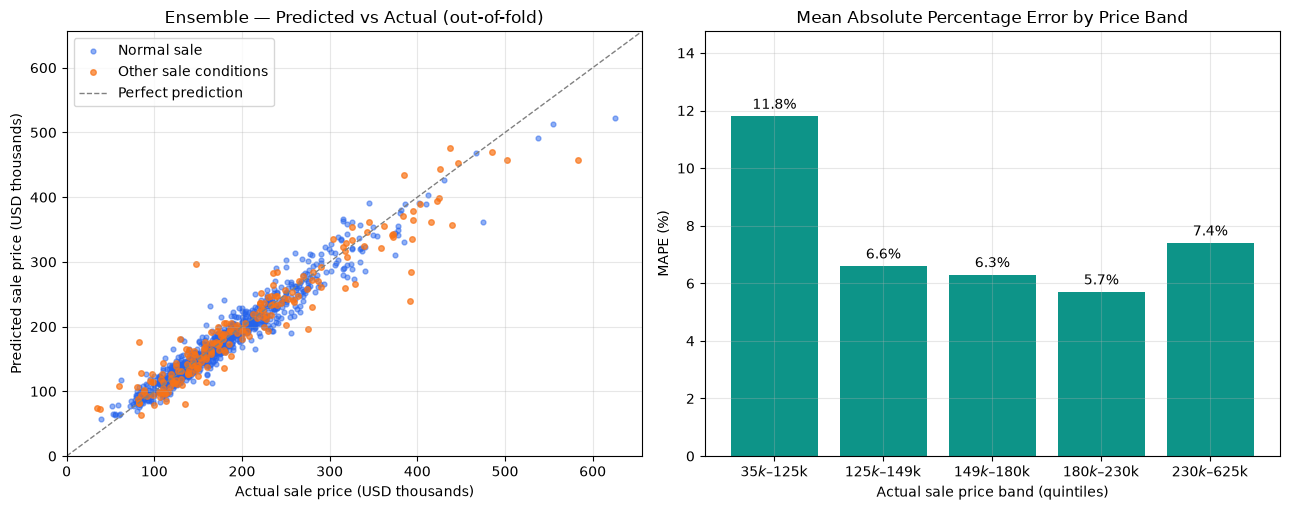

In [9]:
# Lesson 16 — Step 8: Residual analysis of the ensemble (out-of-fold predictions)
ens_oof = cross_val_predict(ensemble, X_train, y_train, cv=cv)

res = pd.DataFrame({
    "Actual": y_train,
    "Predicted": ens_oof,
    "SaleCondition": X_train["SaleCondition"],
})
res["Error"] = res["Predicted"] - res["Actual"]
res["Abs % error"] = res["Error"].abs() / res["Actual"] * 100

# --- Error by price band (quintiles of actual price) ---
edges = np.quantile(res["Actual"], np.linspace(0, 1, 6))
labels = [f"${edges[i]/1000:.0f}k–${edges[i+1]/1000:.0f}k" for i in range(5)]
res["Price band"] = pd.cut(res["Actual"], bins=edges, labels=labels, include_lowest=True)

band_table = res.groupby("Price band", observed=True).agg(
    Homes=("Actual", "size"),
    MAE=("Error", lambda e: e.abs().mean()),
    MAPE=("Abs % error", "mean"),
    Mean_error=("Error", "mean"),
).round(1)
print("ERROR BY PRICE BAND (positive mean error = over-predicted):")
display(band_table)

# --- Error by sale condition ---
cond_table = res.groupby("SaleCondition").agg(
    Homes=("Actual", "size"),
    MAPE=("Abs % error", "mean"),
    Mean_error=("Error", "mean"),
).sort_values("Homes", ascending=False).round(1)
print("\nERROR BY SALE CONDITION:")
display(cond_table)

# --- Figure: predicted vs actual, and MAPE by price band ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.2))
normal = res["SaleCondition"] == "Normal"
ax1.scatter(res.loc[normal, "Actual"] / 1000, res.loc[normal, "Predicted"] / 1000,
            s=12, alpha=0.5, color="#2563EB", label="Normal sale")
ax1.scatter(res.loc[~normal, "Actual"] / 1000, res.loc[~normal, "Predicted"] / 1000,
            s=16, alpha=0.7, color="#F97316", label="Other sale conditions")
lims = [0, res[["Actual", "Predicted"]].max().max() / 1000 * 1.05]
ax1.plot(lims, lims, color="gray", linestyle="--", linewidth=1, label="Perfect prediction")
ax1.set(xlim=lims, ylim=lims, title="Ensemble — Predicted vs Actual (out-of-fold)",
        xlabel="Actual sale price (USD thousands)", ylabel="Predicted sale price (USD thousands)")
ax1.legend(loc="upper left")

bars = ax2.bar(band_table.index.astype(str), band_table["MAPE"], color="#0D9488")
ax2.bar_label(bars, fmt="%.1f%%", padding=3)
ax2.set(title="Mean Absolute Percentage Error by Price Band",
        xlabel="Actual sale price band (quintiles)", ylabel="MAPE (%)")
ax2.set_ylim(0, band_table["MAPE"].max() * 1.25)
for ax in (ax1, ax2):
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Step 9 — Final Test-Set Evaluation and Uncertainty

The ensemble (selected by cross-validation) and the two models it combines are refitted on the full training set and evaluated once on the 291 held-out homes. A paired bootstrap (2,000 resamples) gives 95% confidence intervals for each model's MAE and for the difference between the ensemble and Lasso.

In [10]:
# Lesson 16 — Step 9: Final test evaluation with bootstrap confidence intervals
from sklearn.metrics import (mean_absolute_error, root_mean_squared_error,
                             mean_absolute_percentage_error, r2_score)

final_models = {
    "Ensemble (Lasso + LightGBM)": ensemble,
    "Lasso (alpha tuned)": lasso_pipe,
    "LightGBM (tuned)": lgbm_tuned,
    "Baseline (median price)": DummyRegressor(strategy="median"),
}

test_pred, rows = {}, []
for name, model in final_models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    test_pred[name] = pred
    rows.append({
        "Model": name,
        "MAE ($)": mean_absolute_error(y_test, pred),
        "RMSE ($)": root_mean_squared_error(y_test, pred),
        "MAPE (%)": mean_absolute_percentage_error(y_test, pred) * 100,
        "R2": r2_score(y_test, pred),
    })
print(f"TEST SET RESULTS (n = {len(y_test)} homes ≤ 4,000 sq ft):")
display(pd.DataFrame(rows).round(3))

# --- Paired bootstrap for MAE ---
rng = np.random.default_rng(42)
y_true = y_test.to_numpy()
compare = ["Ensemble (Lasso + LightGBM)", "Lasso (alpha tuned)", "LightGBM (tuned)"]
boot = {name: [] for name in compare}
diff = []
for _ in range(2000):
    idx = rng.integers(0, len(y_true), len(y_true))
    maes = {name: np.mean(np.abs(test_pred[name][idx] - y_true[idx])) for name in compare}
    for name in compare:
        boot[name].append(maes[name])
    diff.append(maes["Ensemble (Lasso + LightGBM)"] - maes["Lasso (alpha tuned)"])

ci_df = pd.DataFrame([{
    "Model": name,
    "Test MAE ($)": mean_absolute_error(y_test, test_pred[name]),
    "95% CI lower ($)": np.percentile(boot[name], 2.5),
    "95% CI upper ($)": np.percentile(boot[name], 97.5),
} for name in compare])
print("\nTEST MAE WITH 95% BOOTSTRAP CONFIDENCE INTERVALS:")
display(ci_df.round(0))

lo, hi = np.percentile(diff, [2.5, 97.5])
print(f"Ensemble − Lasso MAE: {np.mean(diff):+,.0f} $ (95% CI {lo:+,.0f} to {hi:+,.0f})")
print("→ Interval excludes 0: the ensemble's advantage is likely real." if hi < 0
      else "→ Interval includes 0: no clear evidence that the ensemble beats Lasso.")

TEST SET RESULTS (n = 291 homes ≤ 4,000 sq ft):


,Model,MAE ($),RMSE ($),MAPE (%),R2
0,Ensemble (Lasso + LightGBM),13749.013,21235.602,8.684,0.931
1,Lasso (alpha tuned),14182.736,21308.752,8.916,0.931
2,LightGBM (tuned),14861.696,22690.857,9.200,0.921
3,Baseline (median price),57745.460,81808.700,35.829,-0.021



TEST MAE WITH 95% BOOTSTRAP CONFIDENCE INTERVALS:


,Model,Test MAE ($),95% CI lower ($),95% CI upper ($)
0,Ensemble (Lasso + LightGBM),13749.0,11977.0,15684.0
1,Lasso (alpha tuned),14183.0,12412.0,16047.0
2,LightGBM (tuned),14862.0,13034.0,16926.0


Ensemble − Lasso MAE: -438 $ (95% CI -1,014 to +176)
→ Interval includes 0: no clear evidence that the ensemble beats Lasso.


## Step 10 — Publication Figures

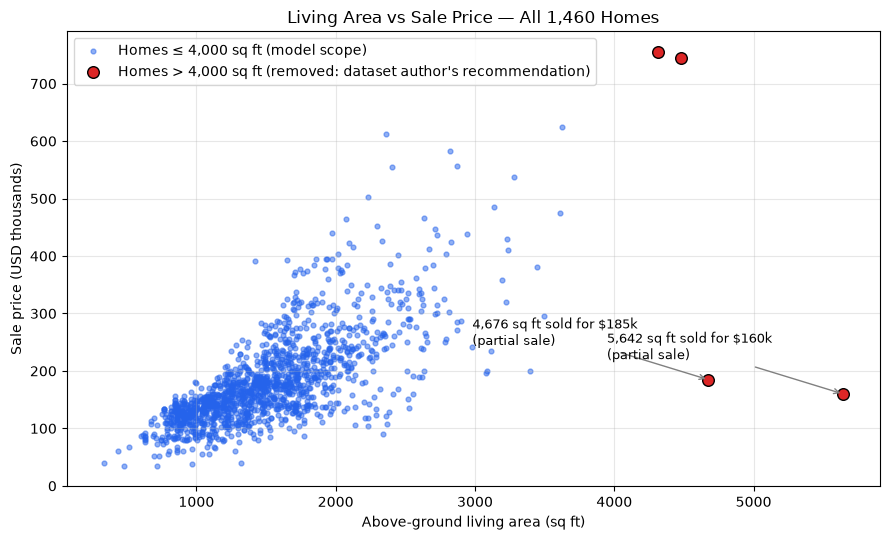

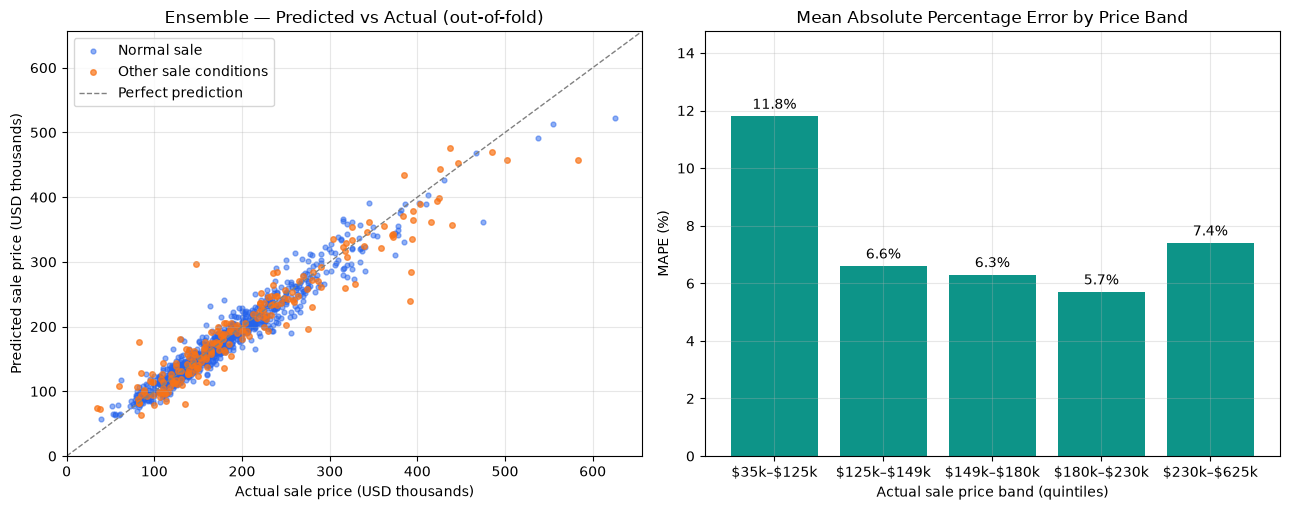

Saved: ['lesson16_outlier_diagnosis.png', 'lesson16_residual_analysis.png']


In [11]:
# Lesson 16 — Step 10: Save publication figures to figures/
from pathlib import Path

fig_dir = Path("figures") if Path("figures").exists() else Path("..") / "figures"

# Figure 1: Outlier diagnosis on the full dataset
big = X["GrLivArea"] > 4000
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.scatter(X.loc[~big, "GrLivArea"], y[~big] / 1000, s=12, alpha=0.5, color="#2563EB",
           label="Homes ≤ 4,000 sq ft (model scope)")
ax.scatter(X.loc[big, "GrLivArea"], y[big] / 1000, s=70, color="#DC2626", edgecolor="black",
           label="Homes > 4,000 sq ft (removed: dataset author's recommendation)")
for _, row in df[big & (df["SaleCondition"] == "Partial") & (df[target] < 250000)].iterrows():
    ax.annotate(f"{row['GrLivArea']:,} sq ft sold for \\${row[target]/1000:.0f}k\n(partial sale)",
                (row["GrLivArea"], row[target] / 1000), textcoords="offset points",
                xytext=(-170, 25), fontsize=9, arrowprops=dict(arrowstyle="->", color="gray"))
ax.set(title=f"Living Area vs Sale Price — All {len(X):,} Homes",
       xlabel="Above-ground living area (sq ft)", ylabel="Sale price (USD thousands)")
ax.grid(alpha=0.3)
ax.legend(loc="upper left")
plt.tight_layout()
fig.savefig(fig_dir / "lesson16_outlier_diagnosis.png", dpi=150, bbox_inches="tight")
plt.show()

# Figure 2: Residual analysis (dollar signs escaped so Matplotlib does not read them as math)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.2))
ax1.scatter(res.loc[normal, "Actual"] / 1000, res.loc[normal, "Predicted"] / 1000,
            s=12, alpha=0.5, color="#2563EB", label="Normal sale")
ax1.scatter(res.loc[~normal, "Actual"] / 1000, res.loc[~normal, "Predicted"] / 1000,
            s=16, alpha=0.7, color="#F97316", label="Other sale conditions")
ax1.plot(lims, lims, color="gray", linestyle="--", linewidth=1, label="Perfect prediction")
ax1.set(xlim=lims, ylim=lims, title="Ensemble — Predicted vs Actual (out-of-fold)",
        xlabel="Actual sale price (USD thousands)", ylabel="Predicted sale price (USD thousands)")
ax1.legend(loc="upper left")

band_labels = [label.replace("$", r"\$") for label in band_table.index.astype(str)]
bars = ax2.bar(band_labels, band_table["MAPE"], color="#0D9488")
ax2.bar_label(bars, fmt="%.1f%%", padding=3)
ax2.set(title="Mean Absolute Percentage Error by Price Band",
        xlabel="Actual sale price band (quintiles)", ylabel="MAPE (%)")
ax2.set_ylim(0, band_table["MAPE"].max() * 1.25)
for ax in (ax1, ax2):
    ax.grid(alpha=0.3)
plt.tight_layout()
fig.savefig(fig_dir / "lesson16_residual_analysis.png", dpi=150, bbox_inches="tight")
plt.show()

print("Saved:", sorted(p.name for p in fig_dir.glob("lesson16_*.png")))

## Conclusions

1. **Diagnosis mattered more than model choice.** Three of 1,168 training homes caused 77.6% of the linear models' squared error. Two of them were partial sales of homes over 4,600 sq ft at ordinary prices, and one cross-validation fold collapsed (R² = −0.24). Following the dataset author's recommendation, homes over 4,000 sq ft were removed from training and test sets (3 + 1 homes). Lasso's R² rose from 0.636 to 0.931, and its variation across folds fell from SD 0.443 to 0.005. **Model scope: homes up to 4,000 sq ft.**
2. **Missing values were mostly structural.** For pools, fireplaces, garages and basements, every missing category value (2,261 of 2,261 rows) matched a zero in the related measurement, so they were recoded as "None". Only four columns needed imputation.
3. **Regularised linear models were the strongest single models** (Lasso CV MAE \$13,459, R² 0.931). Lasso kept 102 of 256 encoded columns. On a log-price scale, house prices behave largely additively.
4. **The boosting family:** XGBoost, scikit-learn Gradient Boosting and LightGBM gave near-identical accuracy with the same settings (CV MAE \$14,247–\$14,507), confirming they implement the same algorithm. XGBoost and LightGBM were about 4 times faster. AdaBoost was clearly weaker (MAE \$20,164). Tuned LightGBM reached \$13,764.
5. **Combining models helped.** Lasso and LightGBM errors were correlated at 0.75. Averaging them gave the best CV result (MAE \$12,876, MAPE 7.6%) and the best test result (MAE \$13,749, R² 0.931, against \$57,745 for the median baseline). The ensemble's test advantage over Lasso (−\$438; 95% CI −\$1,014 to +\$176) was not statistically confirmed.
6. **Where errors remain.** Accuracy is lowest for the cheapest homes (MAPE 11.8% for \$35k–\$125k) and for family and abnormal sales (15–16%). Predictions are pulled toward the middle: low-priced homes are over-predicted (+\$4,855) and high-priced homes under-predicted (−\$9,690).

**Limitations:** one city (Ames, Iowa), sales from 2006–2010, homes up to 4,000 sq ft, and a 291-home test set. Prices reflect that market and period only. For education only.